# Generate variable

In [ ]:
from google.colab import drive
import pandas as pd
import numpy as np
import zipfile
import copy
import matplotlib.pyplot as plt
import seaborn as sns
import datetime

In [ ]:
# pd.set_option('display.max_columns', 1000)
pd.set_option('display.max_rows', None)

In [ ]:
drive.mount('/content/gdrive/')

Mounted at /content/gdrive/


In [ ]:
df1 = pd.read_csv('/content/gdrive/MyDrive/DASS_project/data/preprocessed_ver.csv')

### rename

In [ ]:
df1.columns

Index(['Unnamed: 0', 'sno', 'sna', 'tot', 'sbi', 'sarea', 'bemp', 'act',
       'infoTime', 'infoDate'],
      dtype='object')

In [ ]:
df1 = df1.drop(['Unnamed: 0'], axis = 'columns')

In [ ]:
df1.rename(columns = {'sno':'station_number'}, inplace = True)
df1.rename(columns = {'sna':'station_name'}, inplace = True)
df1.rename(columns = {'tot':'total_num'}, inplace = True)
df1.rename(columns = {'sbi':'current_num'}, inplace = True)
df1.rename(columns = {'bemp':'empty_num'}, inplace = True)
df1.rename(columns = {'sare':'district'}, inplace = True)
df1.rename(columns = {'infoDate':'date'}, inplace = True)
df1.rename(columns = {'infoTime':'time'}, inplace = True)
df1.rename(columns = {'act':'station_status'}, inplace = True)

In [ ]:
df1.columns

Index(['station_number', 'station_name', 'total_num', 'current_num', 'sarea',
       'empty_num', 'station_status', 'time', 'date'],
      dtype='object')

### station distribution

In [ ]:
df1.nunique()

station_number     1233
station_name       1236
total_num            64
current_num          97
sarea                14
empty_num           100
station_status        2
time              61003
date                 18
dtype: int64

In [ ]:
df1['station_number'].value_counts()

500111065    15681
500112065    15680
500104061    15680
500119063    15680
500107026    15680
             ...  
500104103    15674
500112091    15674
500112094    15674
500108140      842
500111086      841
Name: station_number, Length: 1233, dtype: int64

In [ ]:
df1['station_name'].value_counts()

YouBike2.0_中坡市民路口(東北側)      15681
YouBike2.0_松德公園             15680
YouBike2.0_臺大第二行政大樓南側       15680
YouBike2.0_建國長春路口           15680
YouBike2.0_國立故宮博物院          15680
                            ...  
YouBike2.0_?公公園              4080
YouBike2.0_崇仰公園(公?路255巷)     4080
YouBike2.0_糖?文化園區            4080
YouBike2.0_臺北花市               842
YouBike2.0_東新街63巷口            841
Name: station_name, Length: 1236, dtype: int64

### station number station name 不一致（raw data 就這樣）


In [ ]:
station = df1['station_name'].value_counts()
plt.scatter(station.index, station.values)
plt.show()

### 編號 500108140 500111086 在raw_df 1202-1204 裡面沒有

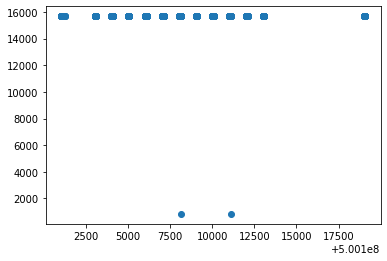

In [ ]:
station_n = df1['station_number'].value_counts()
plt.scatter(station_n.index, station_n.values)
plt.show()

In [ ]:
station_n

500111065    15681
500112065    15680
500104061    15680
500119063    15680
500107026    15680
             ...  
500104103    15674
500112091    15674
500112094    15674
500108140      842
500111086      841
Name: station_number, Length: 1233, dtype: int64

In [ ]:
print(station_n.index[-5:])
print(station_n.values[-5:])

Int64Index([500104103, 500112091, 500112094, 500108140, 500111086], dtype='int64')
[15674 15674 15674   842   841]


### check null 太大跑不出來⋯⋯

In [ ]:
plt.figure(figsize=(21,9))
sns.heatmap(df1.isnull(),yticklabels=False,cbar=False,cmap='viridis')
plt.show()

## time

In [ ]:
df1['date'] = pd.to_datetime(df1['date'])
df1['time'] = pd.to_datetime(df1['time'])

In [ ]:
df1['time']

0          2022-12-02 20:05:05
1          2022-12-02 20:05:05
2          2022-12-02 19:58:12
3          2022-12-02 19:52:38
4          2022-12-02 20:03:13
                   ...        
19299903   2022-12-13 22:38:39
19299904   2022-12-13 22:30:15
19299905   2022-12-13 23:03:04
19299906   2022-12-13 22:08:38
19299907   2022-12-13 18:41:14
Name: time, Length: 19299908, dtype: datetime64[ns]

In [ ]:
df1.dtypes

station_number             int64
station_name              object
total_num                  int64
current_num                int64
sarea                     object
empty_num                  int64
station_status             int64
time              datetime64[ns]
date              datetime64[ns]
dtype: object

### create week

In [ ]:
import time 
from time import strftime

In [ ]:
type(df1['date'][1])

pandas._libs.tslibs.timestamps.Timestamp

In [ ]:
df1['date'][1].strftime("%v")

'%v'

In [ ]:
df1['date'][1].day

2

In [ ]:
new = np.zeros((df1.shape[0]))
print(new.shape)
df1.insert(df1.shape[1], 'day_week', new)

(19299908,)


In [ ]:
df1.columns

Index(['station_number', 'station_name', 'total_num', 'current_num', 'sarea',
       'empty_num', 'station_status', 'time', 'date', 'day_week'],
      dtype='object')

In [ ]:
## 有些資料不更新ㄟ
df1[df1['time'] == '2022-10-25 07:27:04']

,station_number,station_name,total_num,current_num,sarea,empty_num,station_status,time,date,day_week
255,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
1486,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
2717,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
3948,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
5179,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
...,...,...,...,...,...,...,...,...,...,...
19293998,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
19295231,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
19296464,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0
19297697,500104042,YouBike2.0_銘傳大學,30,0,士林區,25,0,2022-10-25 07:27:04,2022-10-25,0.0


In [ ]:
# day fo week
count = 0
#原始方法
def isWeekday(x):
  if x.month != 12:
    return 'error'
    
  else:
    if x.day == 4 or x.day == 11:
      return 'sun'
    elif x.day == 5 or  x.day == 12 :
      return 'mon'
    elif x.day == 6 or  x.day == 13:
      return 'tues'
    elif x.day == 7 or  x.day == 14:
      return 'wen'
    elif x.day == 1 or  x.day == 8:
      return 'thur'
    elif x.day == 2 or  x.day == 9:
      return 'fri'
    elif x.day == 3 or  x.day == 10:
      return 'sat'
    else:
      return 'error'
    # count +=1
    # print(x, ': error of weekday')

df1['day_week'] = df1['time'].apply(isWeekday)

In [ ]:
df1['day_week'].value_counts()

sat      3590470
mon      3529730
tues     3227811
sun      3208645
fri      2092917
wen      1831741
thur     1708855
error     109739
Name: day_week, dtype: int64

In [ ]:
df1 = df1[df1['day_week'] != 'error']

In [ ]:
df1['day_week'].value_counts()

sat     3590470
mon     3529730
tues    3227811
sun     3208645
fri     2092917
wen     1831741
thur    1708855
Name: day_week, dtype: int64

### create time interval

In [ ]:
df1['time'][0:100]

0     2022-12-02 20:05:05
1     2022-12-02 20:05:05
2     2022-12-02 19:58:12
3     2022-12-02 19:52:38
4     2022-12-02 20:03:13
              ...        
96    2022-12-02 19:57:12
97    2022-12-02 20:04:14
98    2022-12-02 19:50:11
99    2022-12-02 20:01:13
100   2022-12-02 20:04:39
Name: time, Length: 100, dtype: datetime64[ns]

In [ ]:
df1.sort_values(by = 'time', inplace = True)
df1[0:100]

,station_number,station_name,total_num,current_num,sarea,empty_num,station_status,time,date,day_week
40373,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
29294,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
13291,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
69917,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
3443,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
51452,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
58838,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
55145,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
31756,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri
15753,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02,fri


In [ ]:
# 去除重複項只有只有1731390筆
df2 = df1.drop_duplicates( keep='last')

In [ ]:
df1.count()

station_number    19190169
station_name      19190169
total_num         19190169
current_num       19190169
sarea             19190169
empty_num         19190169
station_status    19190169
time              19190169
date              19190169
day_week          19190169
dtype: int64

In [ ]:
df2.count()

station_number    1731390
station_name      1731390
total_num         1731390
current_num       1731390
sarea             1731390
empty_num         1731390
station_status    1731390
time              1731390
date              1731390
day_week          1731390
dtype: int64

In [ ]:
df2.to_csv('/content/gdrive/MyDrive/DASS_project/data/1225variable_ver.csv')

In [ ]:
df2 = pd.read_csv('/content/gdrive/MyDrive/DASS_project/data/1225variable_ver.csv')

In [ ]:
df2.columns

Index(['station_number', 'station_name', 'total_num', 'current_num', 'sarea',
       'empty_num', 'station_status', 'time', 'date', 'day_week'],
      dtype='object')

In [ ]:
df2 = df2.drop(['Unnamed: 0'], axis = 'columns')

In [ ]:
df2

,station_number,station_name,total_num,current_num,sarea,empty_num,station_status,time,date,day_week
0,500111052,YouBike2.0_胡適公園,20,2,南港區,18,1,2022-12-02 13:22:39,2022-12-02 00:00:00,fri
1,500105051,YouBike2.0_博嘉運動公園,12,2,文山區,10,1,2022-12-02 13:44:12,2022-12-02 00:00:00,fri
2,500108126,YouBike2.0_安泰街(康樂橋下),15,3,內湖區,12,1,2022-12-02 14:12:39,2022-12-02 00:00:00,fri
3,500109080,YouBike2.0_福國承德路口,15,9,北投區,6,1,2022-12-02 16:15:39,2022-12-02 00:00:00,fri
4,500111113,YouBike2.0_內湖機廠(港東街),15,1,南港區,14,1,2022-12-02 16:38:14,2022-12-02 00:00:00,fri
...,...,...,...,...,...,...,...,...,...,...
1731385,500108076,YouBike2.0_行善路25巷口,14,4,內湖區,10,1,2022-12-13 23:14:03,2022-12-13 00:00:00,tues
1731386,500106015,YouBike2.0_捷運古亭站(8號出口),15,0,中正區,15,1,2022-12-13 23:14:03,2022-12-13 00:00:00,tues
1731387,500101109,YouBike2.0_臺灣師範大學(圖書館),33,1,大安區,12,1,2022-12-13 23:14:03,2022-12-13 00:00:00,tues
1731388,500106043,YouBike2.0_捷運善導寺站(1號出口),33,0,中正區,33,1,2022-12-13 23:14:03,2022-12-13 00:00:00,tues


In [ ]:
df2['station_name'].value_counts()

YouBike2.0_捷運公館站(3號出口)            8404
YouBike2.0_捷運科技大樓站                6333
YouBike2.0_捷運中山國中站                6064
YouBike2.0_捷運行天宮站(3號出口)           5954
YouBike2.0_捷運劍潭站(2號出口)            5773
YouBike2.0_捷運芝山站(2號出口)_1          5446
YouBike2.0_捷運六張犁站                 5291
YouBike2.0_捷運大安站(4號出口)            5273
YouBike2.0_捷運中山站(2號出口)            5176
YouBike2.0_捷運東門站(5號出口)            5132
YouBike2.0_和平龍泉街口                 5050
YouBike2.0_捷運永春站(2號出口)            5047
YouBike2.0_捷運龍山寺站(1號出口)           5041
YouBike2.0_捷運圓山站(1號出口)            4977
YouBike2.0_捷運國父紀念館站(2號出口)         4976
YouBike2.0_捷運南京三民站(1號出口)          4973
YouBike2.0_臺北醫學大學                 4825
YouBike2.0_捷運芝山站(1號出口)            4822
YouBike2.0_捷運台北101/世貿站(2號出口)      4795
YouBike2.0_捷運忠孝復興站(2號出口)          4791
YouBike2.0_臺大第一活動中心西南側            4764
YouBike2.0_捷運信義安和站(4號出口)          4743
YouBike2.0_捷運北投站(1號出口)            4693
YouBike2.0_捷運劍南路站(2號出口)           4641
YouBike2.0_松仁路95巷口                4619
YouBike2.0_捷運石牌站(2號出口)   

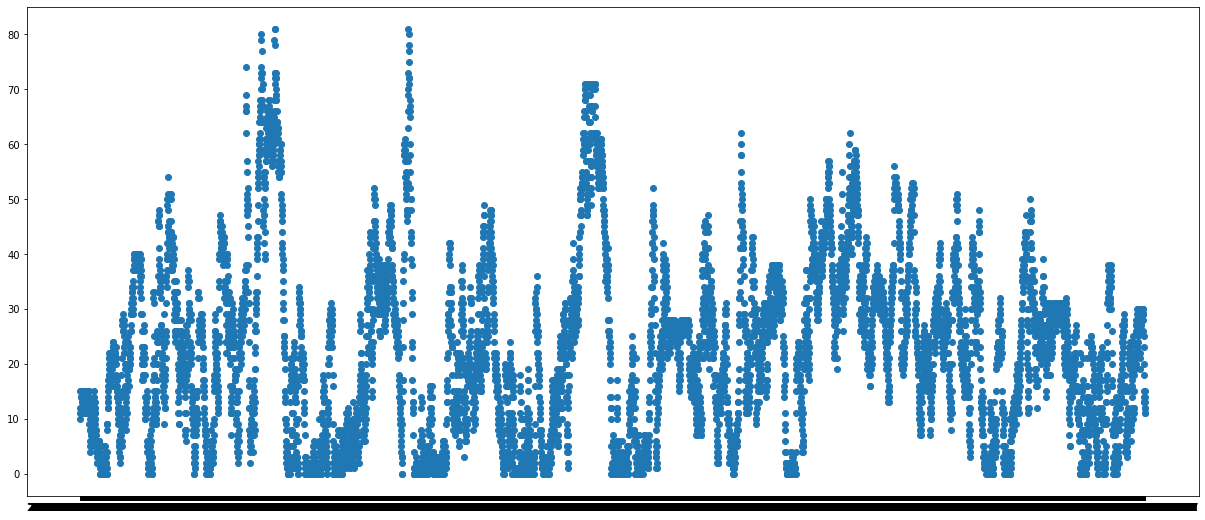

In [ ]:
plt.figure(figsize = (21,9))
plt.scatter( df2[df2['station_name'] == 'YouBike2.0_捷運公館站(3號出口)']['time'], df2[df2['station_name'] == 'YouBike2.0_捷運公館站(3號出口)']['current_num'])
# df2['time']

station_name
YouBike2.0_?公公園                   AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_一壽橋                    AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_一江公園                   AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三張犁                    AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三民公園                   AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三民公園(塔悠路)              AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三民國中(民權東路六段47巷)        AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三民路166巷口               AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三興公園                   AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三興國小                   AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三軍總醫院                  AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_三軍總醫院(松山分院)            AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_下埤公園                   AxesSubplot(0.125,0.125;0.775x0.755)
YouBike2.0_下灣公園                   AxesSubplot(0.125,0.125;0.775x

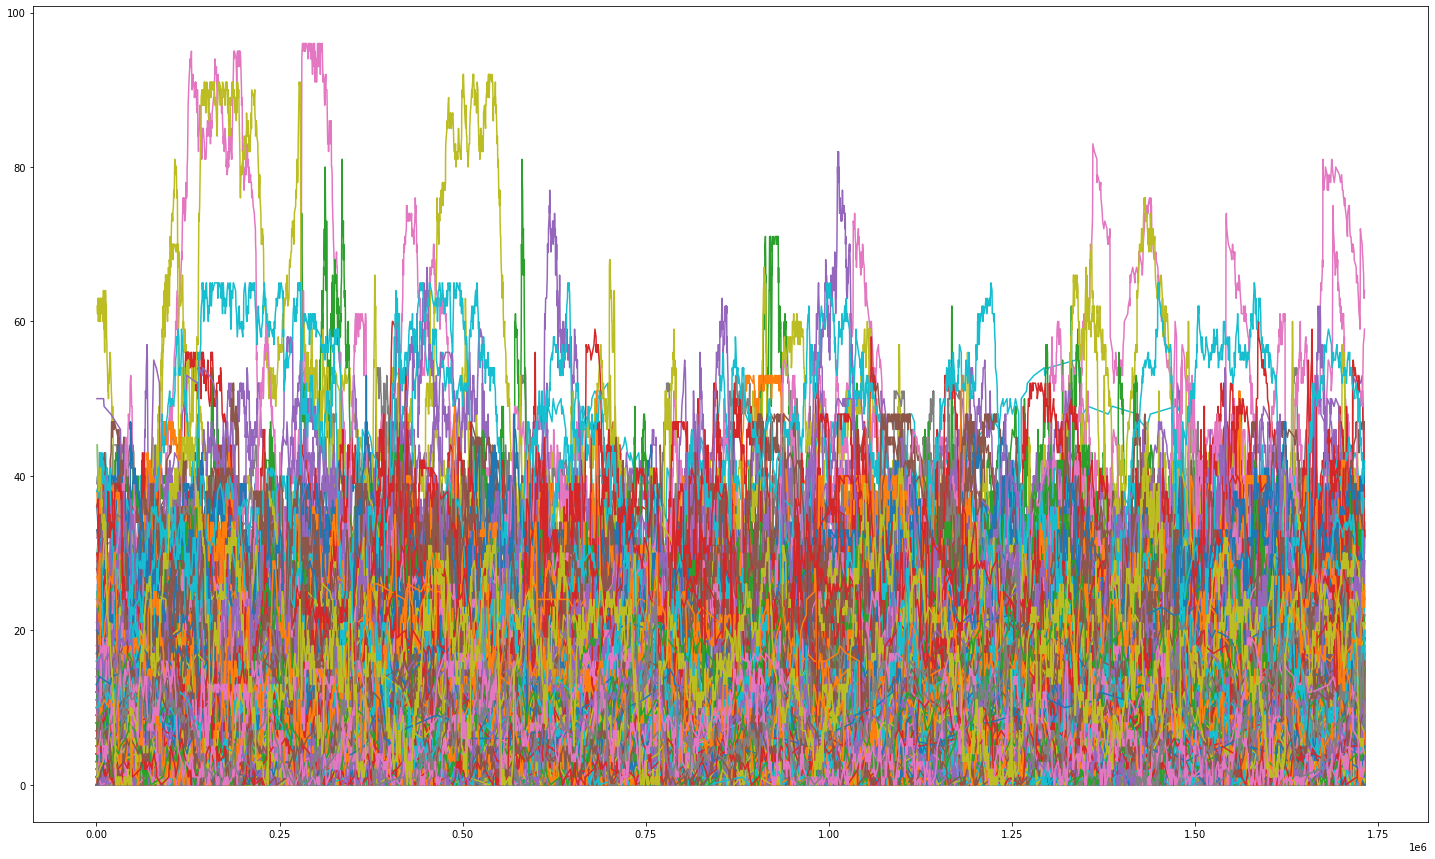

In [ ]:
# df2.set_index()
plt.figure(figsize = (25,15))
df2.groupby(['station_name'])['current_num'].plot()

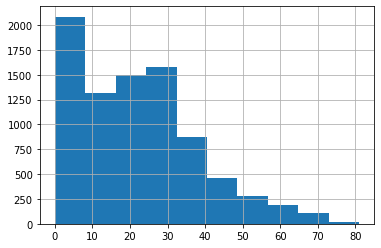

In [ ]:
df2[df2['station_name'] == 'YouBike2.0_捷運公館站(3號出口)']['current_num'].hist()

In [ ]:
# df2['current_num'].hist(by = df2['station_name'])

In [ ]:
df2[df2['station_name'] == 'YouBike2.0_捷運公館站(3號出口)']['time']

1010       2022-12-02 20:04:14
1408       2022-12-02 20:06:03
1597       2022-12-02 20:07:04
1710       2022-12-02 20:07:39
1931       2022-12-02 20:08:39
2311       2022-12-02 20:10:39
2423       2022-12-02 20:11:14
2615       2022-12-02 20:12:13
2779       2022-12-02 20:13:13
3161       2022-12-02 20:15:04
3881       2022-12-02 20:18:38
4265       2022-12-02 20:21:04
4382       2022-12-02 20:21:29
4646       2022-12-02 20:23:04
4740       2022-12-02 20:23:39
4947       2022-12-02 20:24:39
5202       2022-12-02 20:26:04
5868       2022-12-02 20:29:38
6091       2022-12-02 20:30:39
6202       2022-12-02 20:31:45
6380       2022-12-02 20:32:39
6536       2022-12-02 20:33:39
6659       2022-12-02 20:34:13
6882       2022-12-02 20:35:39
7090       2022-12-02 20:36:39
7297       2022-12-02 20:37:38
7380       2022-12-02 20:38:12
7559       2022-12-02 20:39:12
7900       2022-12-02 20:41:04
8748       2022-12-02 20:45:39
9010       2022-12-02 20:47:03
9194       2022-12-02 20:48:04
9311    

公館
1. 4.的資料基本沒有
2. 2. 3. 有缺
3. 其他完整

In [ ]:
df2[df2['station_name'] == 'YouBike2.0_臺大原分所北側']['time'].values


616        2022-12-02 19:59:39
2270       2022-12-02 20:10:19
6262       2022-12-02 20:31:45
10167      2022-12-02 20:53:13
12829      2022-12-02 21:08:39
14687      2022-12-02 21:18:14
17253      2022-12-02 21:32:39
17457      2022-12-02 21:33:39
17705      2022-12-02 21:35:04
72612      2022-12-03 10:06:13
72868      2022-12-03 10:08:04
85674      2022-12-03 11:25:15
103279     2022-12-03 12:53:40
112915     2022-12-03 13:39:13
113836     2022-12-03 13:43:14
116774     2022-12-03 13:56:16
160316     2022-12-03 17:01:13
175991     2022-12-03 18:05:39
182432     2022-12-03 18:33:39
195436     2022-12-03 19:42:40
207161     2022-12-03 20:58:12
229524     2022-12-04 01:04:12
230147     2022-12-04 01:18:11
237602     2022-12-04 06:27:38
242331     2022-12-04 07:41:38
243477     2022-12-04 07:54:12
247563     2022-12-04 08:32:12
252162     2022-12-04 09:04:39
252691     2022-12-04 09:08:13
253274     2022-12-04 09:12:12
254866     2022-12-04 09:23:12
256409     2022-12-04 09:33:38
257228  

### 統一時間

In [ ]:
class time(self):
  def __init__(self, bikes):

def timeIntervel(x):



IndentationError: ignored

In [ ]:
print(df2.groupby(['station_name'])['time'].value_counts())

IOPub data rate exceeded.
The notebook server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--NotebookApp.iopub_data_rate_limit`.

Current values:
NotebookApp.iopub_data_rate_limit=1000000.0 (bytes/sec)
NotebookApp.rate_limit_window=3.0 (secs)



In [ ]:
station_data = df2['station_name'].value_counts()
count = 0
for i in range(station_data.values.shape[0]):
  if station_data.values[i] >= 4032 :
    print(station_data.index[i])
    count +=1

YouBike2.0_捷運公館站(3號出口)
YouBike2.0_捷運科技大樓站
YouBike2.0_捷運中山國中站
YouBike2.0_捷運行天宮站(3號出口)
YouBike2.0_捷運劍潭站(2號出口)
YouBike2.0_捷運芝山站(2號出口)_1
YouBike2.0_捷運六張犁站
YouBike2.0_捷運大安站(4號出口)
YouBike2.0_捷運中山站(2號出口)
YouBike2.0_捷運東門站(5號出口)
YouBike2.0_和平龍泉街口
YouBike2.0_捷運永春站(2號出口)
YouBike2.0_捷運龍山寺站(1號出口)
YouBike2.0_捷運圓山站(1號出口)
YouBike2.0_捷運國父紀念館站(2號出口)
YouBike2.0_捷運南京三民站(1號出口)
YouBike2.0_臺北醫學大學
YouBike2.0_捷運芝山站(1號出口)
YouBike2.0_捷運台北101/世貿站(2號出口)
YouBike2.0_捷運忠孝復興站(2號出口)
YouBike2.0_臺大第一活動中心西南側
YouBike2.0_捷運信義安和站(4號出口)
YouBike2.0_捷運北投站(1號出口)
YouBike2.0_捷運劍南路站(2號出口)
YouBike2.0_松仁路95巷口
YouBike2.0_捷運石牌站(2號出口)
YouBike2.0_臺灣科技大學後門
YouBike2.0_臺大大一女舍北側
YouBike2.0_松山車站
YouBike2.0_捷運市政府站(3號出口)
YouBike2.0_捷運圓山站(2號出口)
YouBike2.0_臺灣科技大學側門
YouBike2.0_捷運雙連站(2號出口)
YouBike2.0_捷運南京復興站(5號出口)
YouBike2.0_臺北市立圖書館(總館)
YouBike2.0_捷運松江南京站(7號出口)
YouBike2.0_捷運公館站(1號出口)
YouBike2.0_臺灣師範大學(圖書館)
YouBike2.0_百齡國小
YouBike2.0_南京遼寧街口
YouBike2.0_捷運臺大醫院站(4號出口)
YouBike2.0_林森長春路口
YouBike2.0_捷運大安森林公園站(5號出口)
YouBike2.0_捷運士林站(2號出口)
YouBike2.0_捷運古亭站(

In [ ]:
print(count)

45
